# Assignment 6: Comparing representations across two layers of a rotated MNIST network with representations across 2 layers of a constrainted rotated MNIST network

Every MNIST image is rotated by a random angle between 0° and 360°, and we keep each image's angle. We train a small MLP (784 → 256 → 64 → 10) to name the digit, then compare hidden layer 1 (256 units) with hidden layer 2 (64 units). Linear method: PCA. Nonlinear method: t-SNE. We also compare tuning curves and RDMs.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.stats import spearmanr
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
import math
import random

torch.manual_seed(0); np.random.seed(0)
train = datasets.MNIST('data', train=True, download=True)
test = datasets.MNIST('data', train=False, download=True)

In [2]:
class RotatedMNIST(Dataset):
    def __init__(self, base_dataset, min_digit: int, max_digit: int, min_rotation_deg: float, max_rotation_deg: float):
        self.base_dataset = base_dataset # the original MNIST dataset
        self.min_rotation_deg = min_rotation_deg
        self.max_rotation_deg = max_rotation_deg

        # Filter dataset using max_digit:
        valid_indices = torch.where((base_dataset.targets >= min_digit) & (base_dataset.targets <= max_digit))[0]
        self.indices = valid_indices.tolist()

    def __len__(self):
        # Return the length of the filtered dataset, not the whole dataset:
        return len(self.indices)

    def __getitem__(self, idx):
        # Map the requested index to the actual index in the dataset:
        real_idx = self.indices[idx]

        # Retrieve the base image tensor and digit label:
        img_tensor, digit_label = self.base_dataset[real_idx]

        # Generate a random angle (0 to max_rotation parameter value)
        angle_deg = random.uniform(self.min_rotation_deg, self.max_rotation_deg)
        angle_rad = math.radians(angle_deg)

        # Rotate the image tensor
        img_rotated = TF.rotate(img_tensor, angle_deg, fill=0)

        img_tensor = TF.to_tensor(img_rotated)

        # Convert continuous radian angle into a 2-value tensor (Sin and Cos)
        # $$$ Not using currently, but may consider if it improves accuracy
        # sin_cos_target = torch.tensor([math.sin(angle_rad), math.cos(angle_rad)], dtype=torch.float32)

        return img_tensor, digit_label, angle_rad, angle_deg

In [3]:
train_data = RotatedMNIST(
    base_dataset=train, 
    min_digit=0, # Defaults to 0 if not found
    max_digit=9, # Defaults to 9 if not found
    min_rotation_deg=0,
    max_rotation_deg=360
)
    
test_data = RotatedMNIST(
    base_dataset=test, 
    min_digit=0,
    max_digit=9,
    min_rotation_deg=0,
    max_rotation_deg=360
)

In [4]:
class TwoHeadedNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Flatten(),
                                  nn.Linear(784, 256),
                                  nn.ReLU(),
                                  nn.Linear(256, 64),
                                  nn.ReLU())
        self.digit_head = nn.Linear(64, 10)
        self.angle_head = nn.Linear(64, 24)

    def forward(self, x):
        h = self.body(x)
        return self.digit_head(h), self.angle_head(h)

In [5]:
class TwoHeadedNNDrop(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Flatten(),
                                  nn.Linear(784, 256),
                                  nn.ReLU(),
                                  nn.Dropout(0.3),
                                  nn.Linear(256, 64),
                                  nn.ReLU(),
                                  nn.Dropout(0.3))
        self.digit_head = nn.Linear(64, 10)
        self.angle_head = nn.Linear(64, 24)

    def forward(self, x):
        h = self.body(x)
        return self.digit_head(h), self.angle_head(h)

In [6]:
# net = nn.Sequential(nn.Flatten(), 
#                     nn.Linear(784, 256), 
#                     nn.ReLU(),
#                     nn.Linear(256, 64), 
#                     nn.ReLU(), 
#                     nn.Linear(64, 10))

# opt = torch.optim.Adam(net.parameters(), lr=1e-3)

# train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
# test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)

# for epoch in range(8):
#     net.train()
#     for images, labels, _, _ in train_loader:
#         opt.zero_grad()
#         output = net(images)
#         loss = F.cross_entropy(output, labels)
#         loss.backward()
#         opt.step()

# net.eval()
# all_X, all_y, all_angles = [], [], []
# with torch.no_grad():
#     for images, labels, _, angles in test_loader:
#         all_X.append(images)
#         all_y.append(labels)
#         all_angles.append(angles)

# X = torch.cat(all_X, dim=0)
# y = torch.cat(all_y, dim=0).numpy()
# angle = torch.cat(all_angles, dim=0).numpy()

# with torch.no_grad():
#     preds = net(X).argmax(dim=1).numpy()
#     print('Test accuracy:', (preds == y).mean())

#     # Extract intermediate representations
#     h1 = net[:3](X).numpy() # Flatten -> Linear(256) -> ReLU
#     h2 = net[:5](X).numpy() # ... -> Linear(64) -> ReLU

# layers = {'Layer 1 (256 units)': h1, 'Layer 2 (64 units)': h2}
# angle_bin = (angle // 30).astype(int)

In [7]:
net = TwoHeadedNN()
opt = torch.optim.Adam(net.parameters(), lr=1e-3)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)

for epoch in range(8):
    net.train()
    for images, digit_labels, _, angles in train_loader:
        angle_labels = (angles // 15).long().clamp(max=23)
        opt.zero_grad()
        digit_output, angle_output = net(images)
        loss = F.cross_entropy(digit_output, digit_labels) + F.cross_entropy(angle_output, angle_labels)
        loss.backward()
        opt.step()

net.eval()
all_X, all_y, all_angles = [], [], []
with torch.no_grad():
    for images, labels, _, angles in test_loader:
        all_X.append(images)
        all_y.append(labels)
        all_angles.append(angles)

X = torch.cat(all_X, dim=0)
y = torch.cat(all_y, dim=0).numpy()
angle = torch.cat(all_angles, dim=0).numpy()

angle_class = (angle // 15).astype(int).clip(max=23)
angle_bin   = (angle // 30).astype(int)

with torch.no_grad():
    digit_out, angle_out = net(X)
    digit_pred = digit_out.argmax(1).numpy()
    angle_pred = angle_out.argmax(1).numpy()

    print('Test Digit Accuracy:', (digit_pred == y).mean())
    print('Test Rotation Accuracy:', (angle_pred == angle_class).mean())

    diff = np.abs(angle_pred - angle_class); diff = np.minimum(diff, 24 - diff)
    print('Rotation within 15 Degrees:  ', (diff <= 1).mean())
    
    h1 = net.body[:3](X).numpy() # Flatten -> Linear(256) -> ReLU
    h2 = net.body[:5](X).numpy() # ... -> Linear(64) -> ReLU

layers = {'Layer 1 (256 units)': h1, 'Layer 2 (64 units)': h2}

Test Digit Accuracy: 0.9059
Test Rotation Accuracy: 0.7019
Rotation within 15 Degrees:   0.9415


In [8]:
net2 = TwoHeadedNNDrop()
opt2 = torch.optim.Adam(net2.parameters(), lr=1e-3)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)

for epoch in range(8):
    net2.train()
    for images, digit_labels, _, angles in train_loader:
        angle_labels = (angles // 15).long().clamp(max=23)
        opt2.zero_grad()
        digit_output, angle_output = net2(images)
        loss = F.cross_entropy(digit_output, digit_labels) + F.cross_entropy(angle_output, angle_labels)
        loss.backward()
        opt2.step()

net2.eval()
all_X2, all_y2, all_angles2 = [], [], []
with torch.no_grad():
    for images, labels, _, angles in test_loader:
        all_X2.append(images)
        all_y2.append(labels)
        all_angles2.append(angles)

X2 = torch.cat(all_X2, dim=0)
y2 = torch.cat(all_y2, dim=0).numpy()
angle2 = torch.cat(all_angles2, dim=0).numpy()

angle_class2 = (angle2 // 15).astype(int).clip(max=23)
angle_bin2   = (angle2 // 30).astype(int)

with torch.no_grad():
    digit_out2, angle_out2 = net2(X2)
    digit_pred2 = digit_out2.argmax(1).numpy()
    angle_pred2 = angle_out2.argmax(1).numpy()

    print('Test Digit Accuracy:', (digit_pred2 == y2).mean())
    print('Test Rotation Accuracy:', (angle_pred2 == angle_class2).mean())

    diff = np.abs(angle_pred2 - angle_class2); diff = np.minimum(diff, 24 - diff)
    print('Rotation within 15 Degrees:  ', (diff <= 1).mean())
    
    h1_2 = net2.body[:3](X2).numpy() # Flatten -> Linear(256) -> ReLU
    h2_2 = net2.body[:5](X2).numpy() # ... -> Linear(64) -> ReLU

layers2 = {'Layer 1 (256 units)': h1_2, 'Layer 2 (64 units)': h2_2}

Test Digit Accuracy: 0.9071
Test Rotation Accuracy: 0.5667
Rotation within 15 Degrees:   0.9321


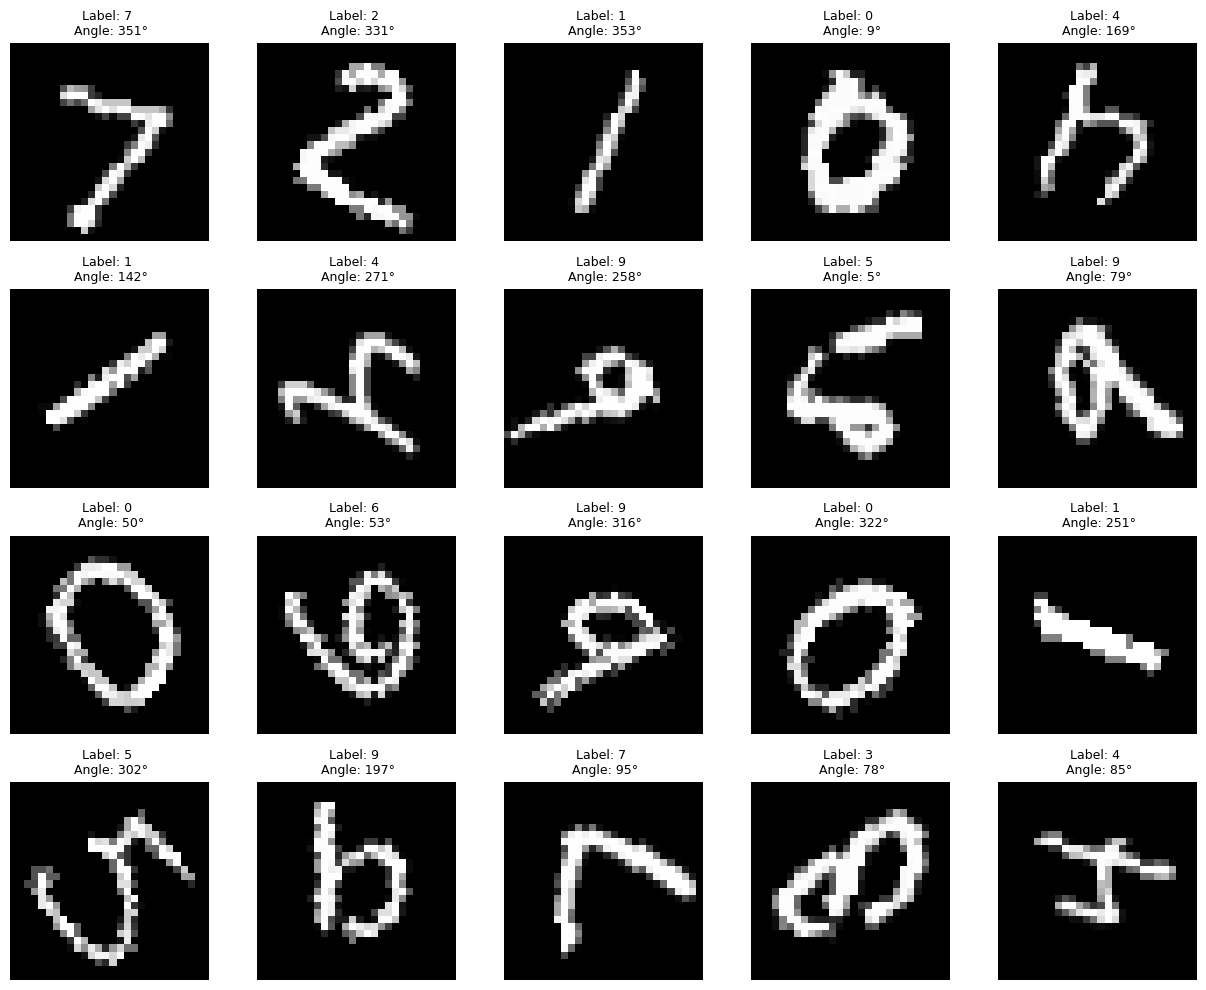

In [9]:
import math

def show_large_grid(dataset, n=25, max_cols=5):
    """Dynamically sizes the figure grid so images never shrink below a readable size."""
    n = min(n, len(dataset))
    cols = min(n, max_cols)
    rows = math.ceil(n / cols)

    # Scale figure dimensions dynamically (e.g., 2.5 inches per image tile)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))

    # Handle edge case where axes might be a single Axes object or 1D array
    if n == 1:
        axes = np.array([axes])
    else:
        axes = axes.flatten()

    for i in range(n):
        img_tensor, digit_label, _, angle_deg = dataset[i]
        img_np = img_tensor.squeeze(0).numpy()

        axes[i].imshow(img_np, cmap='gray')
        axes[i].set_title(f"Label: {digit_label} \n Angle: {angle_deg:.0f}°", fontsize=9)
        axes[i].axis('off')

    # Turn off unused axes if grid has empty slots
    for j in range(n, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

# Example: Display 20 images cleanly in a 5-column layout
show_large_grid(test_data, n=20, max_cols=5)

## Linear (PCA) and nonlinear (t-SNE) views of each layer

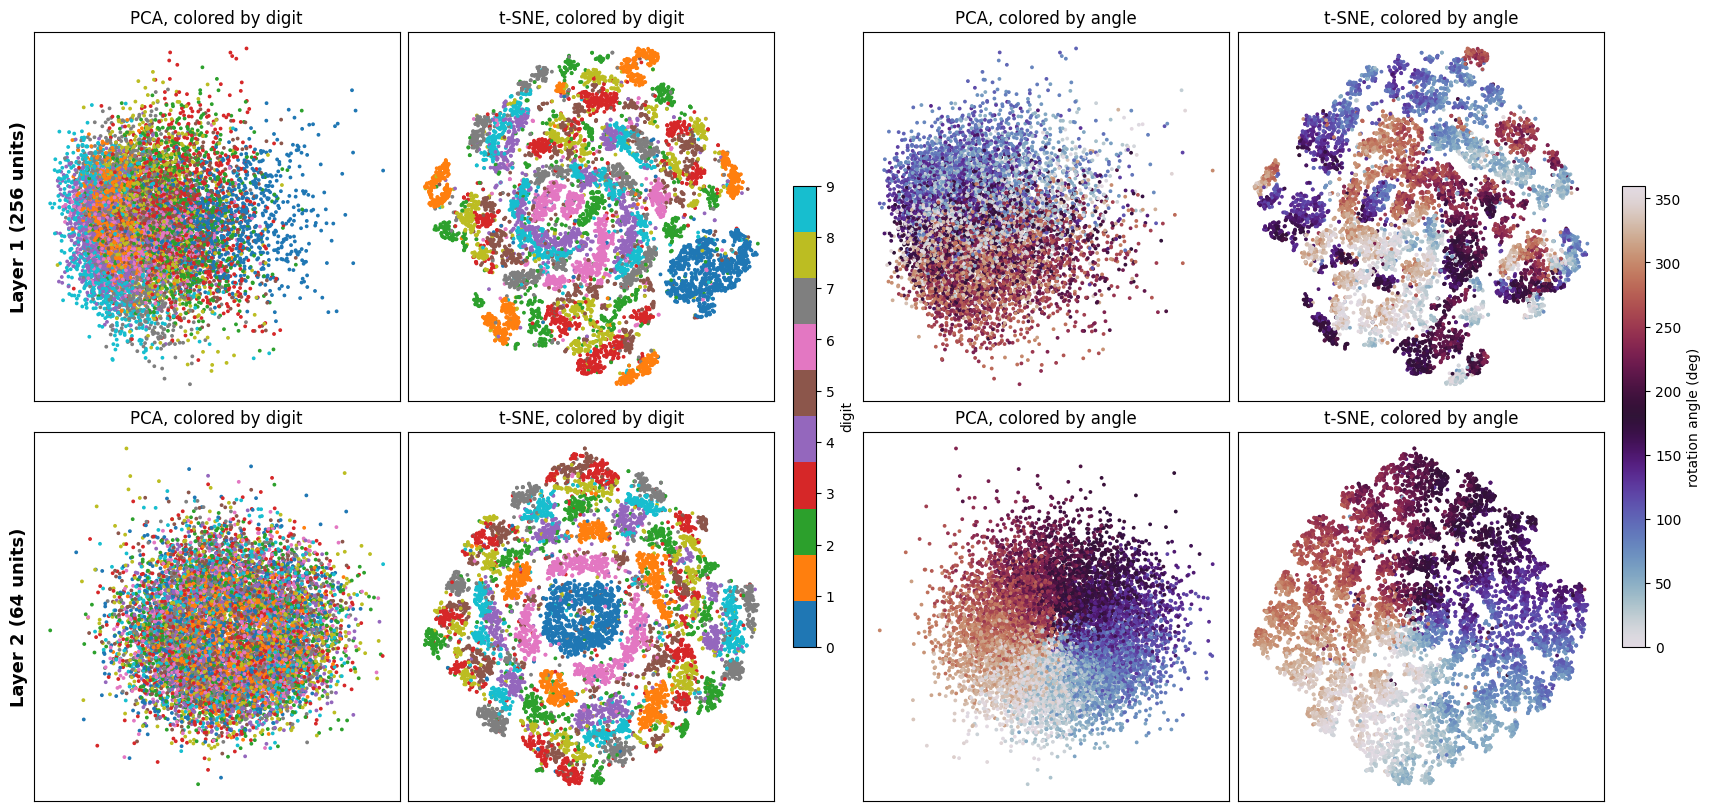

In [10]:
fig, ax = plt.subplots(2, 4, figsize=(17, 8), layout='constrained')
for r, (name, a) in enumerate(layers.items()):
    for c, (emb, method) in enumerate([(PCA(2).fit_transform(a), 'PCA'),
                                       (TSNE(2, random_state=0, init='pca').fit_transform(a), 't-SNE')]):
        s1 = ax[r, c].scatter(*emb.T, c=y, cmap='tab10', s=3)
        s2 = ax[r, c + 2].scatter(*emb.T, c=angle, cmap='twilight', vmin=0, vmax=360, s=3)
        ax[r, c].set(title=f'{method}, colored by digit', xticks=[], yticks=[])
        ax[r, c + 2].set(title=f'{method}, colored by angle', xticks=[], yticks=[])
    ax[r, 0].set_ylabel(name, fontsize=13, fontweight='bold')
fig.colorbar(s1, ax=ax[:, 1], label='digit', shrink=0.6)
fig.colorbar(s2, ax=ax[:, 3], label='rotation angle (deg)', shrink=0.6)
plt.show()

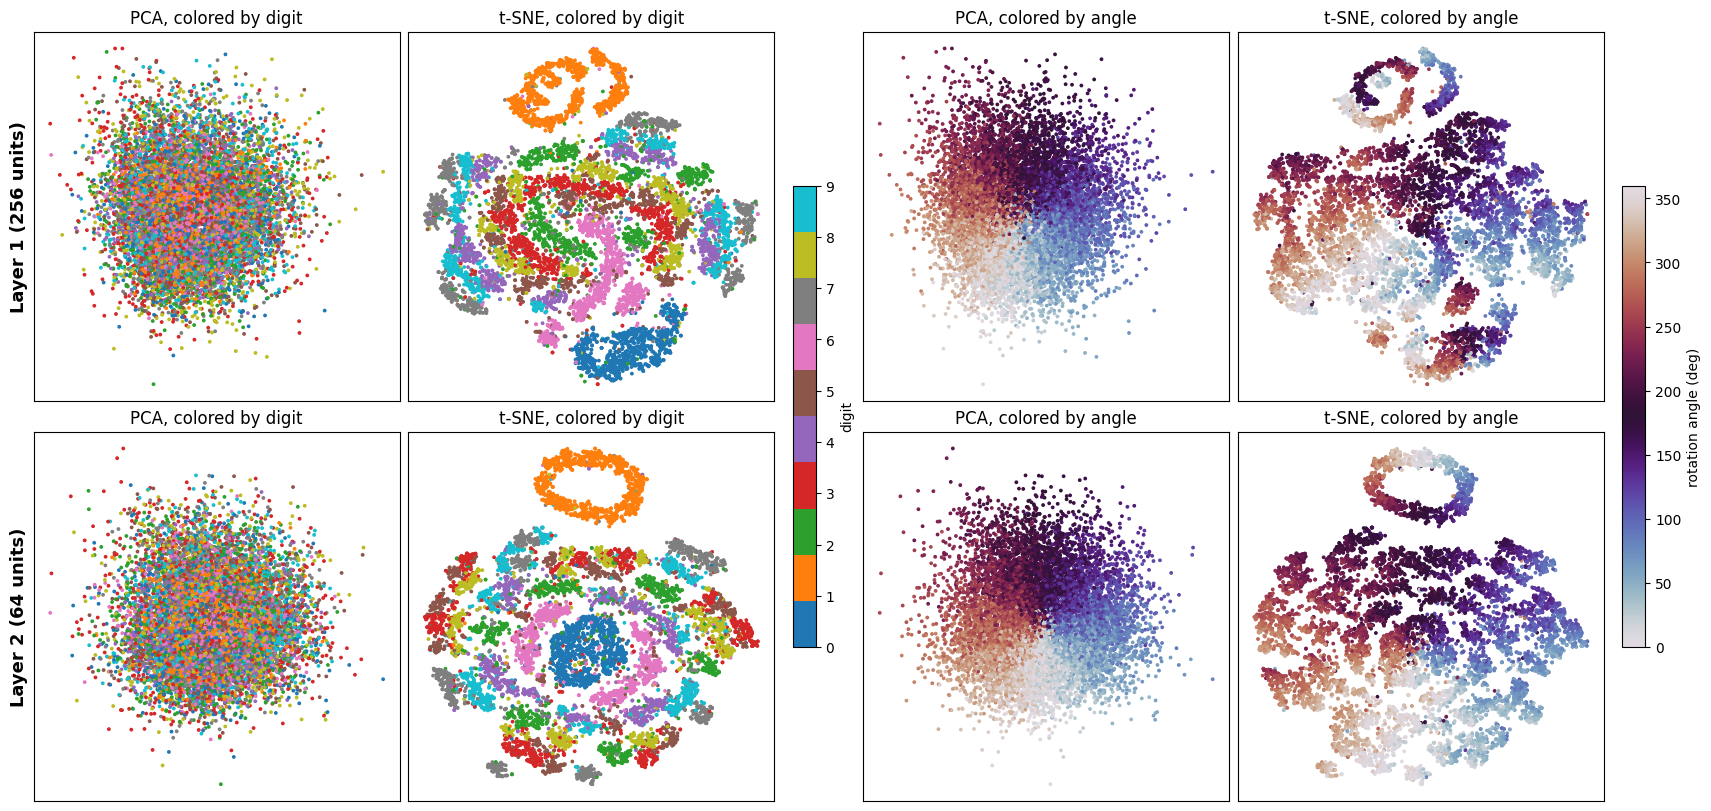

In [11]:
fig, ax = plt.subplots(2, 4, figsize=(17, 8), layout='constrained')
for r, (name, a) in enumerate(layers2.items()):
    for c, (emb, method) in enumerate([(PCA(2).fit_transform(a), 'PCA'),
                                       (TSNE(2, random_state=0, init='pca').fit_transform(a), 't-SNE')]):
        s1 = ax[r, c].scatter(*emb.T, c=y2, cmap='tab10', s=3)
        s2 = ax[r, c + 2].scatter(*emb.T, c=angle2, cmap='twilight', vmin=0, vmax=360, s=3)
        ax[r, c].set(title=f'{method}, colored by digit', xticks=[], yticks=[])
        ax[r, c + 2].set(title=f'{method}, colored by angle', xticks=[], yticks=[])
    ax[r, 0].set_ylabel(name, fontsize=13, fontweight='bold')
fig.colorbar(s1, ax=ax[:, 1], label='digit', shrink=0.6)
fig.colorbar(s2, ax=ax[:, 3], label='rotation angle (deg)', shrink=0.6)
plt.show()

## Tuning curves for digit and rotation angle

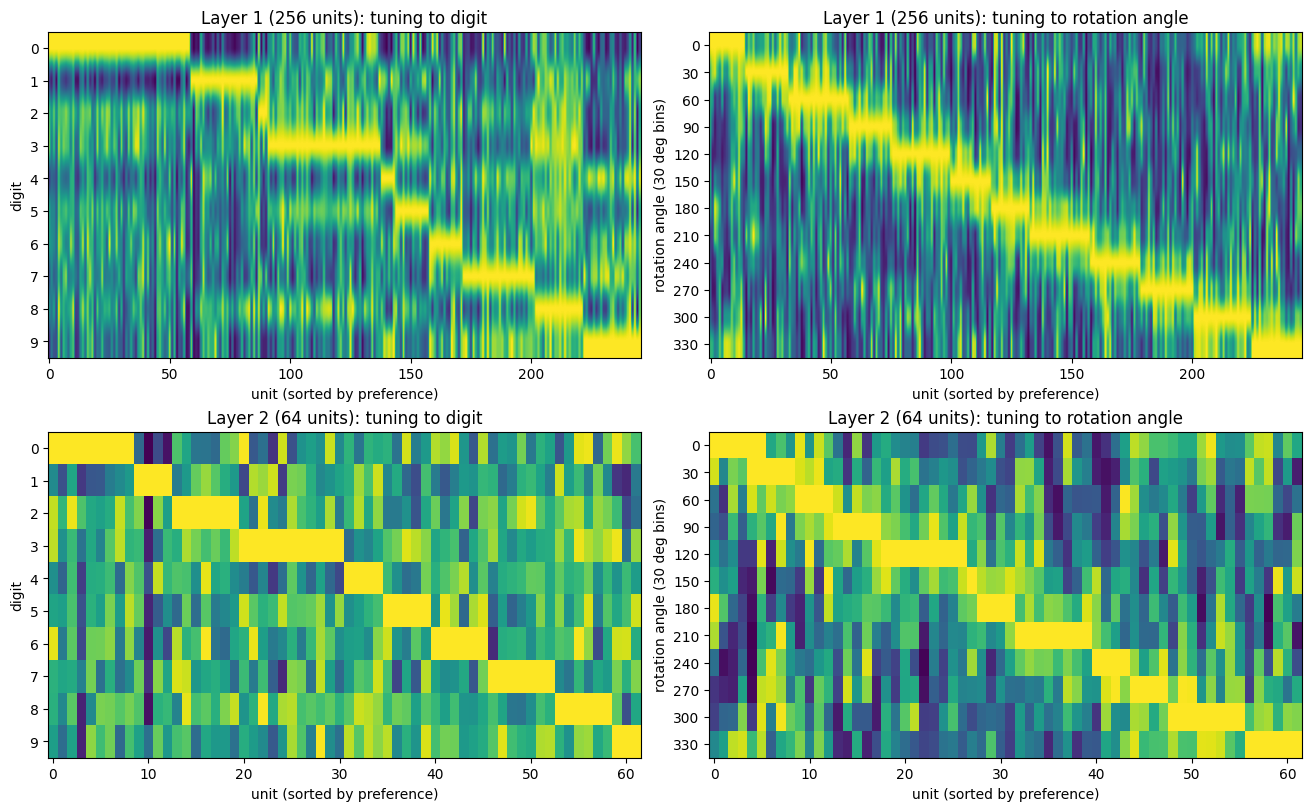

Layer 1 (256 units) {'active units': 246.0, 'digit selectivity': 0.331, 'angle selectivity': 0.378, 'variance explained by digit': 0.089, 'variance explained by angle': 0.137}
Layer 2 (64 units) {'active units': 62.0, 'digit selectivity': 0.246, 'angle selectivity': 0.305, 'variance explained by digit': 0.172, 'variance explained by angle': 0.33}


In [12]:
def tuning(a, labels):
    m = np.array([a[labels == k].mean(0) for k in np.unique(labels)])
    act = m.max(0) > 1e-6
    m = m[:, act]
    best, rest = m.max(0), (m.sum(0) - m.max(0)) / (len(m) - 1)
    explained = m.var(0) / a[:, act].var(0)
    return m, ((best - rest) / (best + rest)).mean(), explained.mean()

fig, ax = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
stats = {}
for r, (name, a) in enumerate(layers.items()):
    md, sel_d, var_d = tuning(a, y)
    ma, sel_a, var_a = tuning(a, angle_bin)
    for c, (m, label, ticks) in enumerate([(md, 'digit', range(10)), (ma, 'rotation angle (30 deg bins)', range(12))]):
        m = m[:, np.argsort(m.argmax(0))]
        ax[r, c].imshow(m / m.max(0), aspect='auto', cmap='viridis')
        ax[r, c].set(title=f'{name}: tuning to {label.split(" (")[0]}', xlabel='unit (sorted by preference)', ylabel=label, yticks=ticks)
    ax[r, 1].set_yticklabels([f'{30 * k}' for k in range(12)])
    stats[name] = {'active units': md.shape[1], 'digit selectivity': sel_d, 'angle selectivity': sel_a,
                   'variance explained by digit': var_d, 'variance explained by angle': var_a}
plt.show()
for name, s in stats.items():
    print(name, {k: round(float(v), 3) for k, v in s.items()})

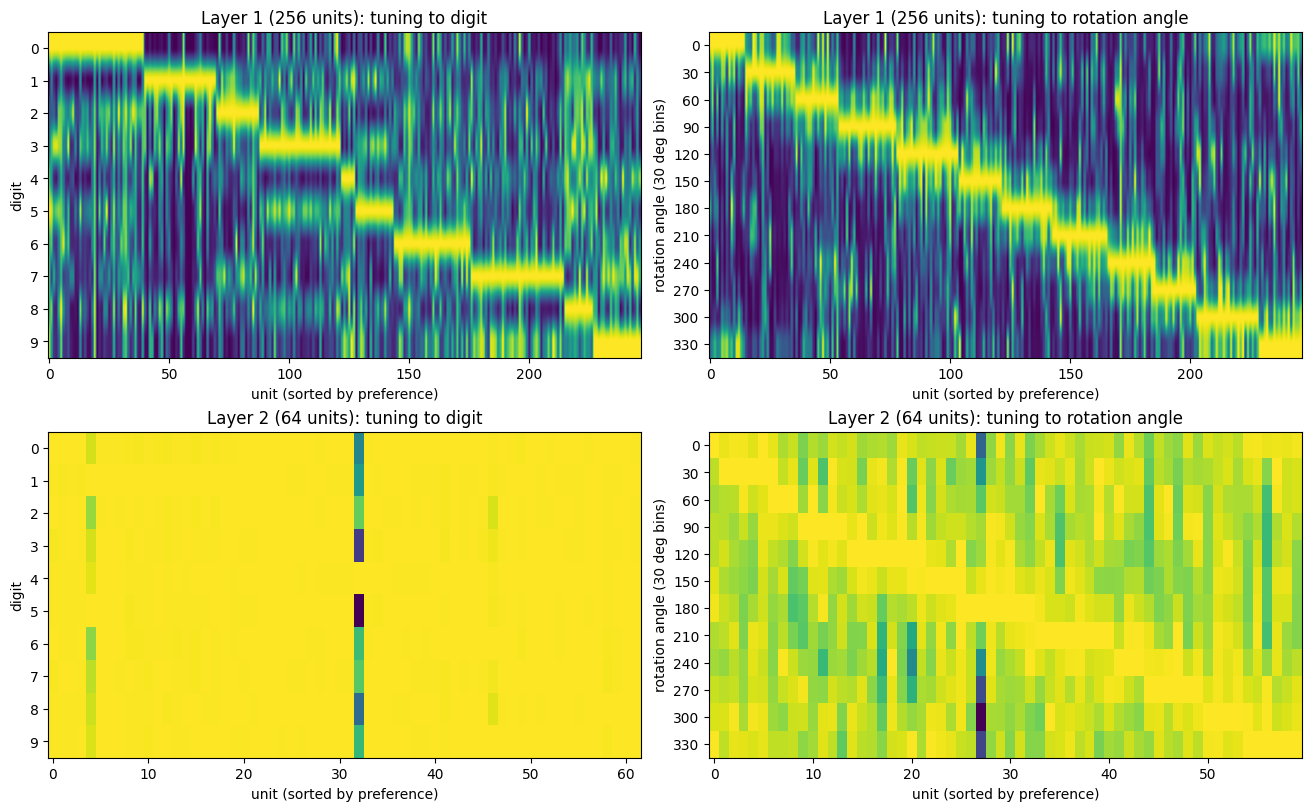

Layer 1 (256 units) {'active units': 247.0, 'digit selectivity': 0.485, 'angle selectivity': 0.528, 'variance explained by digit': 0.091, 'variance explained by angle': 0.14}
Layer 2 (64 units) {'active units': 62.0, 'digit selectivity': -3.538, 'angle selectivity': 0.634, 'variance explained by digit': 0.281, 'variance explained by angle': 0.343}


In [13]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
stats = {}
for r, (name, a) in enumerate(layers2.items()):
    md, sel_d, var_d = tuning(a, y2)
    ma, sel_a, var_a = tuning(a, angle_bin2)
    for c, (m, label, ticks) in enumerate([(md, 'digit', range(10)), (ma, 'rotation angle (30 deg bins)', range(12))]):
        m = m[:, np.argsort(m.argmax(0))]
        ax[r, c].imshow(m / m.max(0), aspect='auto', cmap='viridis')
        ax[r, c].set(title=f'{name}: tuning to {label.split(" (")[0]}', xlabel='unit (sorted by preference)', ylabel=label, yticks=ticks)
    ax[r, 1].set_yticklabels([f'{30 * k}' for k in range(12)])
    stats[name] = {'active units': md.shape[1], 'digit selectivity': sel_d, 'angle selectivity': sel_a,
                   'variance explained by digit': var_d, 'variance explained by angle': var_a}
plt.show()
for name, s in stats.items():
    print(name, {k: round(float(v), 3) for k, v in s.items()})

## RDMs (600 test images, sorted by digit, then angle)

Pixels                 digit model rho = 0.087   angle model rho = 0.046
Layer 1 (256 units)    digit model rho = 0.134   angle model rho = 0.297
Layer 2 (64 units)     digit model rho = 0.171   angle model rho = 0.657


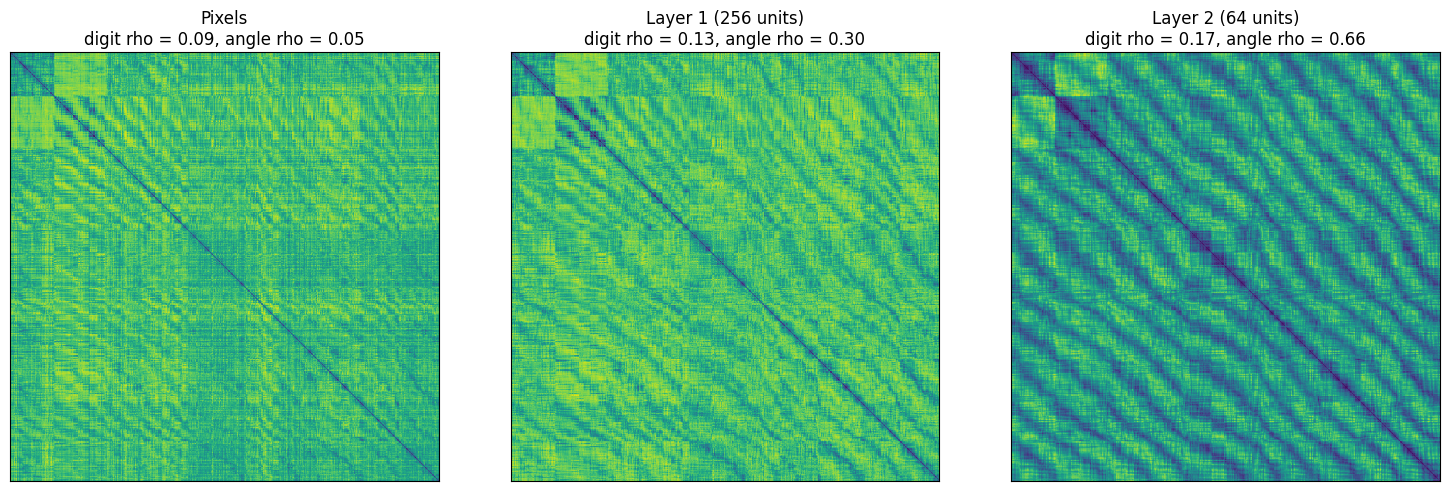

Pixels vs Layer 1 (256 units): rho = 0.719
Pixels vs Layer 2 (64 units): rho = 0.259
Layer 1 (256 units) vs Layer 2 (64 units): rho = 0.610
Layer 1 (256 units) PCs for 90% variance: 84
Layer 2 (64 units) PCs for 90% variance: 17


In [14]:
sub = np.random.choice(len(y), 600, replace=False)
sub = sub[np.lexsort((angle[sub], y[sub]))]
iu = np.triu_indices(len(sub), 1)
digit_model = (y[sub][:, None] != y[sub][None, :]).astype(float)
d = np.abs(angle[sub][:, None] - angle[sub][None, :])
angle_model = np.minimum(d, 360 - d)

def rdm(a):
    return 1 - np.corrcoef(a)

rdms = {'Pixels': rdm(X.flatten(1).numpy()[sub])}
rdms.update({name: rdm(a[sub]) for name, a in layers.items()})
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), layout='constrained')
for i, (name, R) in enumerate(rdms.items()):
    rho_d = spearmanr(R[iu], digit_model[iu])[0]
    rho_a = spearmanr(R[iu], angle_model[iu])[0]
    ax[i].imshow(R, cmap='viridis')
    ax[i].set(title=f'{name}\ndigit rho = {rho_d:.2f}, angle rho = {rho_a:.2f}', xticks=[], yticks=[])
    print(f'{name:22s} digit model rho = {rho_d:.3f}   angle model rho = {rho_a:.3f}')
plt.show()
names = list(rdms)
for i in range(3):
    for j in range(i + 1, 3):
        print(f'{names[i]} vs {names[j]}: rho = {spearmanr(rdms[names[i]][iu], rdms[names[j]][iu])[0]:.3f}')
for name, a in layers.items():
    print(name, 'PCs for 90% variance:', np.searchsorted(np.cumsum(PCA().fit(a).explained_variance_ratio_), 0.9) + 1)

Pixels                 digit model rho = 0.086   angle model rho = -0.001
Layer 1 (256 units)    digit model rho = 0.146   angle model rho = 0.436
Layer 2 (64 units)     digit model rho = 0.199   angle model rho = 0.655


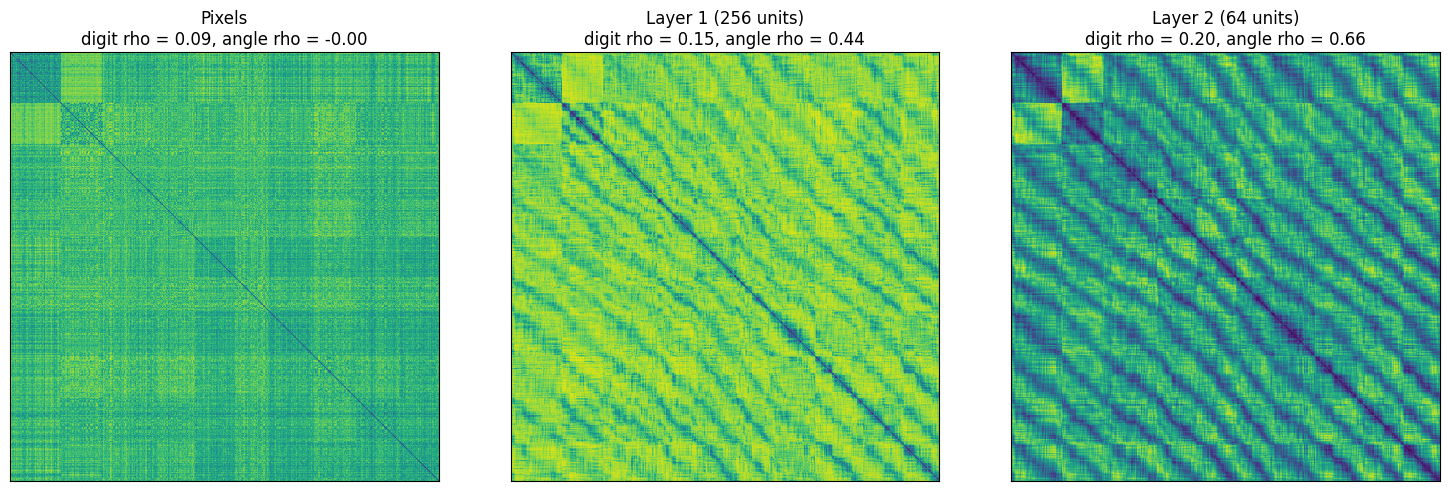

Pixels vs Layer 1 (256 units): rho = 0.181
Pixels vs Layer 2 (64 units): rho = 0.092
Layer 1 (256 units) vs Layer 2 (64 units): rho = 0.734
Layer 1 (256 units) PCs for 90% variance: 84
Layer 2 (64 units) PCs for 90% variance: 17


In [15]:
sub = np.random.choice(len(y2), 600, replace=False)
sub = sub[np.lexsort((angle2[sub], y2[sub]))]
iu = np.triu_indices(len(sub), 1)
digit_model = (y2[sub][:, None] != y2[sub][None, :]).astype(float)
d = np.abs(angle2[sub][:, None] - angle2[sub][None, :])
angle_model = np.minimum(d, 360 - d)

def rdm(a):
    return 1 - np.corrcoef(a)

rdms = {'Pixels': rdm(X.flatten(1).numpy()[sub])}
rdms.update({name: rdm(a[sub]) for name, a in layers2.items()})
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), layout='constrained')
for i, (name, R) in enumerate(rdms.items()):
    rho_d = spearmanr(R[iu], digit_model[iu])[0]
    rho_a = spearmanr(R[iu], angle_model[iu])[0]
    ax[i].imshow(R, cmap='viridis')
    ax[i].set(title=f'{name}\ndigit rho = {rho_d:.2f}, angle rho = {rho_a:.2f}', xticks=[], yticks=[])
    print(f'{name:22s} digit model rho = {rho_d:.3f}   angle model rho = {rho_a:.3f}')
plt.show()
names = list(rdms)
for i in range(3):
    for j in range(i + 1, 3):
        print(f'{names[i]} vs {names[j]}: rho = {spearmanr(rdms[names[i]][iu], rdms[names[j]][iu])[0]:.3f}')
for name, a in layers.items():
    print(name, 'PCs for 90% variance:', np.searchsorted(np.cumsum(PCA().fit(a).explained_variance_ratio_), 0.9) + 1)